In [4]:
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import mlflow
import mlflow.sklearn

from xgboost import XGBClassifier
import seaborn as sns

In [5]:
import mlflow
print("MLflow version:", mlflow.__version__)

import mlflow.sklearn
print("mlflow.sklearn imported successfully")

MLflow version: 3.18.0
mlflow.sklearn imported successfully


In [6]:
df = pd.read_csv("phone_price.csv", skiprows=3)

In [7]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0.0,1,0,7,0.6,188.0,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1.0,0,1,53,0.7,136.0,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1.0,2,1,41,0.9,145.0,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0.0,0,0,10,0.8,131.0,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0.0,13,1,44,0.6,141.0,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [8]:
df.shape

(3000, 21)

In [9]:
df["price_range"].unique()

array([1, 2, 3, 0])

In [10]:
df.dtypes

battery_power      int64
blue               int64
clock_speed      float64
dual_sim         float64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt        float64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w               int64
talk_time          int64
three_g            int64
touch_screen       int64
wifi               int64
price_range        int64
dtype: object

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  3000 non-null   int64  
 1   blue           3000 non-null   int64  
 2   clock_speed    3000 non-null   float64
 3   dual_sim       3000 non-null   float64
 4   fc             3000 non-null   int64  
 5   four_g         3000 non-null   int64  
 6   int_memory     3000 non-null   int64  
 7   m_dep          3000 non-null   float64
 8   mobile_wt      3000 non-null   float64
 9   n_cores        3000 non-null   int64  
 10  pc             3000 non-null   int64  
 11  px_height      3000 non-null   int64  
 12  px_width       3000 non-null   int64  
 13  ram            3000 non-null   int64  
 14  sc_h           3000 non-null   int64  
 15  sc_w           3000 non-null   int64  
 16  talk_time      3000 non-null   int64  
 17  three_g        3000 non-null   int64  
 18  touch_screen   3000

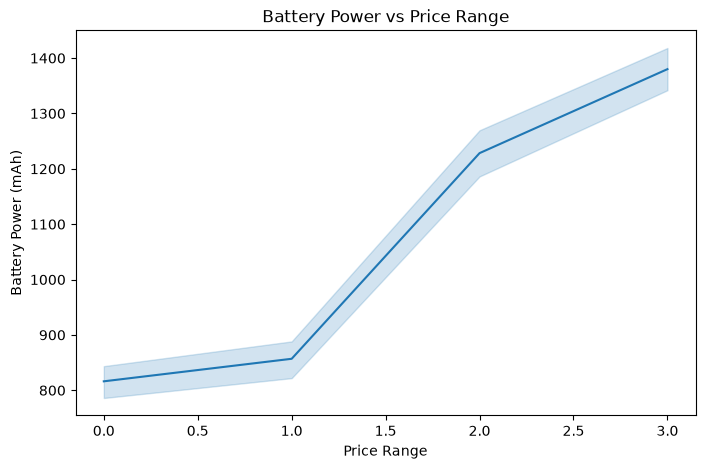

In [13]:
plt.figure(figsize=(8,5))

sns.lineplot(data=df, x="price_range", y="battery_power")

plt.title("Battery Power vs Price Range")
plt.xlabel("Price Range")
plt.ylabel("Battery Power (mAh)")

# Savethe plot localy
plt.savefig("battery_power_vs_price_range.png", dpi=300, bbox_inches="tight")

plt.show()
plt.close()

In [19]:
X=df.drop(columns=["price_range"])
y=df["price_range"]

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,train_size=0.8)

In [21]:
#Define pipeline for numerical values
num_cols=X.select_dtypes(include="number").columns

num_pipe=Pipeline([
    ("Imputer",SimpleImputer(strategy="mean")),
    ("Standardisation",StandardScaler())

])

#Define ColumnTransformer
preprocessing=ColumnTransformer([
    ("preprocessing",num_pipe,num_cols)
])


In [29]:
feature_selected = SelectFromModel(
    XGBClassifier(n_estimators=100, max_depth=10),threshold="mean"
)

In [33]:
#Define ML pipeline

#parameters for RandomForest
rf_params={
    "n_estimators":100,
    "max_depth":30,
    "min_samples_split":2,
    "min_samples_leaf":1,
}

ml_pipeline=Pipeline([
    ("Preprosessing",preprocessing),
    ("features for feature Selection",feature_selected),
    ("Model for prediction",RandomForestClassifier(**rf_params))
])

In [26]:
print(ml_pipeline)

Pipeline(steps=[{ColumnTransformer(transformers=[('preprocessing',
                                                  Pipeline(steps=[('Imputer',
                                                                   SimpleImputer()),
                                                                  ('Standardisation',
                                                                   StandardScaler())]),
                                                  Index(['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g',
       'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height',
       'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wif...
                                                         learning_rate=None,
                                                         max_bin=None,
                                                         max_cat_threshold=None,
                                                         max_cat_to_oneh

In [27]:
print(ml_pipeline.get_params())

{'memory': None, 'steps': [{ColumnTransformer(transformers=[('preprocessing',
                                 Pipeline(steps=[('Imputer', SimpleImputer()),
                                                 ('Standardisation',
                                                  StandardScaler())]),
                                 Index(['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g',
       'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height',
       'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi'],
      dtype='str'))]), 'Preprocessing'}, {'features selected', SelectFromModel(estimator=XGBClassifier(base_score=None, booster=None,
                                        callbacks=None, colsample_bylevel=None,
                                        colsample_bynode=None,
                                        colsample_bytree=None, device=None,
                                        early_stopping_rounds=None,
   

In [34]:
ml_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprosessing', ...), ('features for feature Selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['battery_power','blue','clock_speed',...,'three_g','touch_screen','wifi']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('preprocessing', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [36]:
#Get the feature selection step
selector=ml_pipeline.named_steps["features for feature Selection"]

#Get selected Column mask
selected_features=selector.get_support()

#Get selected column names
selected_columns=X_train.columns[selected_features]

print("selected Features: ")
print(selected_columns.tolist())

selected Features: 
['battery_power', 'blue', 'px_height', 'px_width', 'ram']


In [39]:
y_pred=ml_pipeline.predict(X_test)

acc=accuracy_score(y_test,y_pred)
report=classification_report(y_test,y_pred)

print("Accuracy",acc)
print(report)

Accuracy 0.7783333333333333
              precision    recall  f1-score   support

           0       0.73      0.74      0.73       198
           1       0.71      0.70      0.70       196
           2       0.86      0.87      0.87       101
           3       0.92      0.90      0.91       105

    accuracy                           0.78       600
   macro avg       0.81      0.80      0.80       600
weighted avg       0.78      0.78      0.78       600



In [37]:
# Set an experimental name

mlflow.set_experiment("Model Training using Pipeline")

mlflow.set_tracking_uri("http://127.0.0.1:5000")

2026/11/06 15:43:41 INFO mlflow.tracking.fluent: Experiment with name 'Model Training using Pipeline' does not exist. Creating a new experiment.


In [40]:
import mlflow 
import mlflow.sklearn

#uploading parameters,metrics and model artifacts to MLFlow

with mlflow.start_run(run_name="RandomForestExperiment"):

    #saving log parameters to mlflow
    mlflow.log_params(rf_params)

    #saving numerical metrics
    mlflow.log_metric("Accuracy",acc)

    #saving classification report
    mlflow.log_text(report,"classification_report.txt")

    #Log complete ML pipeline
    mlflow.sklearn.log_model(
        sk_model=ml_pipeline,
        name="Random",
        serialization_format="cloudpickle"
    )

    #saving figure to mlflow
    mlflow.log_artifact(
        "battery_power_vs_price_range.png",#location
        artifact_path="plots"#location in which file saved on mlflow
    )

2026/11/06 16:24:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run RandomForestExperiment at: http://127.0.0.1:5000/#/experiments/1/runs/3e44c90882ef40ad83890ccbff868b13
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
